# Evaluation


In [1]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown
from matplotlib.ticker import AutoMinorLocator

sys.path.append('..')  # repo root, so `scripts` is importable
from scripts.forecasting_helpers import (
    FEATURES, CATEGORICAL_FEATURES, NUMERIC_FEATURES, TARGETS, GROUPING_COLUMNS,
    NFI12_TRAIN_INVNRS, NFI123_TRAIN_INVNRS, NFI12_TEST_INVNR, NFI123_TEST_INVNR,
    CLIP_RANGES, PERSISTENCE_MAP,
    load_best_hyperparams, load_and_clean, encode_features, build_model_inputs,
    train_scope, predict_clip, calculate_all_metrics,
)

# Match the deployment / iterative-prediction seed for reproducibility
np.random.seed(35)

In [2]:
# --- Configuration ---

FILE_PATH = '../data/preprocessed/final_nfi_ch2018_merged/NFI_with_Climate_Averages_RCP45.csv'

# Each setup uses the hyperparameters tuned for its own training horizon.
NFI12_HYPERPARAMS_PATH  = Path('../data/hyperparameters/nfi1/best_params.json')   # NFI12: train INVNR 150, 250
NFI123_HYPERPARAMS_PATH = Path('../data/hyperparameters/nfi12/best_params.json')  # NFI123: train INVNR 150, 250, 350

clip_ranges = CLIP_RANGES
persistence_map = PERSISTENCE_MAP
target_labels = {
    'BASFPH_next_INVNR':    'Next Basal Area (BASFPH_next_INVNR)',
    'HWSW_prop_next_INVNR': 'Next Broadleaf Fraction (HWSW_prop_next_INVNR)',
}

FIG_DIR = '../figures/rolling_window_eval/'
Path(FIG_DIR).mkdir(parents=True, exist_ok=True)

NFI12_HYPERPARAMS = load_best_hyperparams(NFI12_HYPERPARAMS_PATH)
NFI123_HYPERPARAMS = load_best_hyperparams(NFI123_HYPERPARAMS_PATH)
print('NFI12 hyperparameters:', NFI12_HYPERPARAMS_PATH)
print('NFI123 hyperparameters:', NFI123_HYPERPARAMS_PATH)

NFI12 hyperparameters: ../data/hyperparameters/nfi1/best_params.json
NFI123 hyperparameters: ../data/hyperparameters/nfi12/best_params.json


In [3]:
# --- Metric & table helpers ---

def append_summary_metrics(all_results, eval_df, target, model_name, dataset_name, split_feature=None):
    '''Append Overall plus feature-based P90-split metrics for one evaluation slice.'''
    overall = calculate_all_metrics(eval_df['y_true'], eval_df['predictions'], group_name='Overall')
    overall.update({'Target': target, 'Model': model_name, 'DataSet': dataset_name})
    all_results.append(overall)

    if split_feature is None or split_feature not in eval_df.columns:
        return

    thr = eval_df[split_feature].quantile(0.9)
    lower = eval_df[eval_df[split_feature] < thr]
    if not lower.empty:
        m = calculate_all_metrics(lower['y_true'], lower['predictions'],
                                  group_name=f'Lower 90% by {split_feature} (< P90)')
        m.update({'Target': target, 'Model': model_name, 'DataSet': dataset_name})
        all_results.append(m)
    upper = eval_df[eval_df[split_feature] >= thr]
    if not upper.empty:
        m = calculate_all_metrics(upper['y_true'], upper['predictions'],
                                  group_name=f'Upper decile by {split_feature} (>= P90)')
        m.update({'Target': target, 'Model': model_name, 'DataSet': dataset_name})
        all_results.append(m)

def evaluate_predictions(all_results, original_df, y_true, predictions, target,
                         model_name, dataset_name, split_feature, grouping_cols):
    '''Overall + P90 split + per-group metrics for one (model, dataset) slice.'''
    eval_df = original_df.copy()
    eval_df['y_true'] = np.asarray(y_true)
    eval_df['predictions'] = np.asarray(predictions)
    append_summary_metrics(all_results, eval_df, target, model_name, dataset_name, split_feature=split_feature)
    for gc in grouping_cols:
        if gc in eval_df.columns:
            for gv in sorted(eval_df[gc].dropna().unique()):
                gdf = eval_df[eval_df[gc] == gv]
                gm = calculate_all_metrics(gdf['y_true'], gdf['predictions'], group_name=f'{gc}_{gv}')
                gm.update({'Target': target, 'Model': model_name, 'DataSet': dataset_name})
                all_results.append(gm)

MODEL_ORDER = ['XGBoost', 'Lasso', 'Persistence']
MODEL_LABELS = {'XGBoost': 'XGB', 'Lasso': 'Lasso', 'Persistence': 'Persistence'}
DATASET_LABELS = {'Train': 'Train', 'Test': 'Test', 'Iterative_NFI5': 'Iterative NFI5'}
MANAGEMENT_LABELS = {1.0: 'Managed', 2.0: 'Rarely managed', 3.0: 'Unmanaged'}

def ordered_group_rows(all_groups, split_feature=None):
    '''Stable group order plus readable section/group labels for the report tables.'''
    all_groups = set(all_groups)
    bewirt = sorted(
        [g for g in all_groups if g.startswith('BEWIRTINT1_')],
        key=lambda x: float(x.split('_')[-1]),
    )
    naish = sorted(
        [g for g in all_groups if g.startswith('NAISHSTKOMB_')],
        key=lambda x: float(x.split('_')[-1]),
    )

    rows = []
    if 'Overall' in all_groups:
        rows.append(('Overall', 'Overall', 'Overall'))

    if split_feature:
        lower = f'Lower 90% by {split_feature} (< P90)'
        upper = f'Upper decile by {split_feature} (>= P90)'
        if lower in all_groups:
            rows.append(('P90 split', lower, f'{split_feature} < P90'))
        if upper in all_groups:
            rows.append(('P90 split', upper, f'{split_feature} >= P90'))

    rows.extend(('Management intensity', g, MANAGEMENT_LABELS.get(float(g.split('_', 1)[1]), f'Class {g.split("_", 1)[1]}')) for g in bewirt)
    rows.extend(('Vegetation belt', g, f'Class {g.split("_", 1)[1]}') for g in naish)
    return rows

def build_group_table(results_df, target, datasets, metric_specs, split_feature=None, include_n=False):
    '''Readable table builder shared by the summary and R2-only report views.'''
    if isinstance(datasets, str):
        datasets = [datasets]

    subset = results_df[(results_df['Target'] == target) & (results_df['DataSet'].isin(datasets))].copy()
    if subset.empty:
        return pd.DataFrame()

    frames = []
    for dataset in datasets:
        ds_subset = subset[subset['DataSet'] == dataset].copy()
        if ds_subset.empty:
            continue

        layout = pd.DataFrame(
            ordered_group_rows(ds_subset['Group'].unique(), split_feature=split_feature),
            columns=['Section', 'RawGroup', 'Group'],
        )
        if layout.empty:
            continue

        tbl = pd.DataFrame({
            'Sample': DATASET_LABELS.get(dataset, dataset),
            'Section': layout['Section'],
            'Group': layout['Group'],
        })

        if include_n:
            n_wide = (ds_subset.pivot(index='Group', columns='Model', values='N')
                      .reindex(layout['RawGroup']))
            shared_n = (not n_wide.empty) and n_wide.nunique(axis=1, dropna=True).le(1).all()
            if shared_n:
                tbl['N'] = (n_wide.bfill(axis=1).iloc[:, 0]
                            .round(0)
                            .astype('Int64')
                            .to_numpy())
            else:
                for model in MODEL_ORDER:
                    if model in n_wide.columns:
                        tbl[f'{MODEL_LABELS[model]} N'] = (n_wide[model]
                                                          .round(0)
                                                          .astype('Int64')
                                                          .to_numpy())

        for model in MODEL_ORDER:
            model_df = (ds_subset[ds_subset['Model'] == model]
                        .set_index('Group')[['RMSE', 'R_squared', 'Bias']])
            if model_df.empty:
                continue
            for source_col, label, digits in metric_specs:
                tbl[f'{MODEL_LABELS[model]} {label}'] = (
                    layout['RawGroup'].map(model_df[source_col]).round(digits).to_numpy()
                )

        tbl.loc[tbl.index[1:], 'Sample'] = ''
        tbl['Section'] = tbl['Section'].where(~tbl['Section'].duplicated(), '')
        frames.append(tbl)

    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def build_summary_table(results_df, target, datasets, split_feature=None):
    '''Summary table with one shared N column plus RMSE / R2 / Bias by model.'''
    return build_group_table(
        results_df,
        target,
        datasets,
        metric_specs=[('RMSE', 'RMSE', 2), ('R_squared', 'R2', 3), ('Bias', 'Bias', 2)],
        split_feature=split_feature,
        include_n=True,
    )

def display_heading(text, level=2):
    '''Notebook-friendly section header without long print banners.'''
    display(Markdown(f"{'#' * level} {text}"))

def display_metric_tables(case_label, results_df, datasets=('Train', 'Test')):
    '''Render the full metric tables for one case with compact headings.'''
    display_heading(case_label, level=2)
    for target in TARGETS:
        split = persistence_map[target]
        display_heading(target_labels[target], level=3)
        display(build_summary_table(results_df, target, list(datasets), split_feature=split))

In [4]:
# --- Load, clean, and build per-model inputs ---

df = load_and_clean(FILE_PATH, verbose=True)
nfi12_scope = build_model_inputs(df, NFI12_TRAIN_INVNRS)
nfi123_scope = build_model_inputs(df, NFI123_TRAIN_INVNRS)
print('NFI12:', len(nfi12_scope['X_train']), 'train rows,', len(nfi12_scope['final_features']), 'features')
print('NFI123:', len(nfi123_scope['X_train']), 'train rows,', len(nfi123_scope['final_features']), 'features')

Loaded 1560 rows.
After cleaning: 480 rows | unique CLNR: 120
   INVNR 150 : 120 rows
   INVNR 250 : 120 rows
   INVNR 350 : 120 rows
   INVNR 450 : 120 rows
NFI12: 240 train rows, 29 features
NFI123: 360 train rows, 29 features


In [5]:
# --- Train one XGBoost and one Lasso per target, for each NFI setup ---

models_nfi12, imp_nfi12 = train_scope(nfi12_scope, NFI12_HYPERPARAMS)
models_nfi123, imp_nfi123 = train_scope(nfi123_scope, NFI123_HYPERPARAMS)
print('Trained NFI12 and NFI123.')

Trained NFI12 and NFI123.


In [6]:
# --- Train-fit + one-step test evaluation for each NFI setup ---
# NFI12: test = NFI4 (INVNR 350 -> 450).  NFI123: test = NFI5 (INVNR 450 -> 550).
# DataSet label is 'Train' / 'Test' so the table builders and the metric-mean align cleanly.

def evaluate_horizon(scope, models, test_invnr):
    results = []
    plot_data = {t: {} for t in TARGETS}
    test_df = df[df['INVNR'] == test_invnr].copy()
    X_test = encode_features(test_df, scope['cats_map'], scope['final_features'])

    for target in TARGETS:
        split = persistence_map[target]
        lo, hi = clip_ranges[target]
        for algo in ['XGBoost', 'Lasso']:
            model = models[target][algo]
            tr_pred = predict_clip(model, scope['X_train'], target)
            evaluate_predictions(results, scope['train_df'], scope['y_train'][target], tr_pred,
                                 target, algo, 'Train', split, GROUPING_COLUMNS)
            te_pred = predict_clip(model, X_test, target)
            evaluate_predictions(results, test_df, test_df[target], te_pred,
                                 target, algo, 'Test', split, GROUPING_COLUMNS)
            plot_data[target]['y_true'] = test_df[target].values
            plot_data[target][algo] = te_pred
        pf = persistence_map[target]
        tr_pers = np.clip(scope['train_df'][pf].values, lo, hi)
        evaluate_predictions(results, scope['train_df'], scope['y_train'][target], tr_pers,
                             target, 'Persistence', 'Train', split, GROUPING_COLUMNS)
        te_pers = np.clip(test_df[pf].values, lo, hi)
        evaluate_predictions(results, test_df, test_df[target], te_pers,
                             target, 'Persistence', 'Test', split, GROUPING_COLUMNS)
        plot_data[target]['Persistence'] = te_pers
    return pd.DataFrame(results), plot_data, test_df

nfi12_df, plot_nfi12, df_nfi12_test = evaluate_horizon(nfi12_scope, models_nfi12, NFI12_TEST_INVNR)  # NFI4: 350->450
nfi123_df, plot_nfi123, df_nfi123_test = evaluate_horizon(nfi123_scope, models_nfi123, NFI123_TEST_INVNR)  # NFI5: 450->550
print('NFI12 (NFI4, 350->450) and NFI123 (NFI5, 450->550) one-step evaluations complete.')

NFI12 (NFI4, 350->450) and NFI123 (NFI5, 450->550) one-step evaluations complete.


In [7]:
# Iterative NFI5: 350->450->550 on common plots with observed INVNR 350 & 450.

df350_all = df[df['INVNR'] == 350]
df450_all = df[df['INVNR'] == 450]
common_clnr = set(df350_all['CLNR']).intersection(df450_all['CLNR'])
df350_c = df350_all[df350_all['CLNR'].isin(common_clnr)].copy()
df450_c = df450_all[df450_all['CLNR'].isin(common_clnr)].copy()
print('Common plots with observed INVNR 350 & 450:', len(common_clnr))

# --- NFI12 predicts the 450 state from observed INVNR 350 ---
X350 = encode_features(df350_c, nfi12_scope['cats_map'], nfi12_scope['final_features'])
clnr350 = df350_c['CLNR'].values
step1 = {}
for algo in ['XGBoost', 'Lasso']:
    step1[algo] = {
        'BASFPH':    predict_clip(models_nfi12['BASFPH_next_INVNR'][algo],    X350, 'BASFPH_next_INVNR'),
        'HWSW_prop': predict_clip(models_nfi12['HWSW_prop_next_INVNR'][algo], X350, 'HWSW_prop_next_INVNR'),
    }
step1['Persistence'] = {
    'BASFPH':    np.clip(df350_c['BASFPH'].values, 0, 100),
    'HWSW_prop': np.clip(df350_c['HWSW_prop'].values, 0, 1),
}

def s1_to_450(arr):
    '''Map a per-INVNR350 array onto df450_c order via CLNR.'''
    return pd.Series(arr, index=clnr350).reindex(df450_c['CLNR']).values

# --- replace endogenous state in the 450 rows with step-1 predictions, predict 550 ---
iter_results = []
plot_iter = {t: {} for t in TARGETS}
for target in TARGETS:
    split = persistence_map[target]
    lo, hi = clip_ranges[target]
    y_true = df450_c[target].values  # observed 550 state
    plot_iter[target]['y_true'] = y_true
    for algo in ['XGBoost', 'Lasso', 'Persistence']:
        mod450 = df450_c.copy()
        mod450['BASFPH']    = s1_to_450(step1[algo]['BASFPH'])
        mod450['HWSW_prop'] = s1_to_450(step1[algo]['HWSW_prop'])
        if algo == 'Persistence':
            pred = np.clip(mod450[persistence_map[target]].values, lo, hi)  # observed 350 carried forward twice
        else:
            Xmod = encode_features(mod450, nfi12_scope['cats_map'], nfi12_scope['final_features'])
            pred = predict_clip(models_nfi12[target][algo], Xmod, target)
        plot_iter[target][algo] = pred
        evaluate_predictions(iter_results, df450_c, y_true, pred, target, algo,
                             'Iterative_NFI5', split, GROUPING_COLUMNS)
iter_df = pd.DataFrame(iter_results)
print('Recursive (iterative) NFI5 (350->450->550) evaluation complete.')

Common plots with observed INVNR 350 & 450: 120
Recursive (iterative) NFI5 (350->450->550) evaluation complete.


In [8]:
# --- NFI12/NFI123 mean: average the evaluation metrics of {NFI12 @ NFI4} and {NFI123 @ NFI5} ---
# Different one-step horizons on purpose (350->450 vs 450->550); averaged at the metric level
# per Target/Model/DataSet/Group. NFI12 contributes ONLY its one-step (direct) test here.

METRIC_COLS = ['N', 'RMSE', '%RMSE', 'R_squared', 'Bias', '%Bias']
KEYS = ['Target', 'Model', 'DataSet', 'Group']

a = nfi12_df.set_index(KEYS)[METRIC_COLS]
b = nfi123_df.set_index(KEYS)[METRIC_COLS]
common = a.index.intersection(b.index)
mean_df = ((a.loc[common] + b.loc[common]) / 2.0).reset_index()
print('NFI12/NFI123 mean built over', len(common), 'aligned (Target, Model, DataSet, Group) rows.')
print('Note: Mean Test = mean(NFI12@NFI4, NFI123@NFI5); Mean Train = mean(NFI12-train, NFI123-train).')

NFI12/NFI123 mean built over 192 aligned (Target, Model, DataSet, Group) rows.
Note: Mean Test = mean(NFI12@NFI4, NFI123@NFI5); Mean Train = mean(NFI12-train, NFI123-train).


In [9]:
# --- Full metric tables for the direct one-step cases ---
# The NFI12/NFI123 mean is shown later.

full_metric_cases = [
    ('NFI12  (one-step test = NFI4: 350->450)', nfi12_df),
    ('NFI123 (one-step test = NFI5: 450->550, == model_evaluation)', nfi123_df),
]
for case_label, rdf in full_metric_cases:
    display_metric_tables(case_label, rdf)

## NFI12  (one-step test = NFI4: 350->450)

### Next Basal Area (BASFPH_next_INVNR)

,Sample,Section,Group,N,XGB RMSE,XGB R2,XGB Bias,Lasso RMSE,Lasso R2,Lasso Bias,Persistence RMSE,Persistence R2,Persistence Bias
0,Train,Overall,Overall,240,3.59,0.873,-0.01,3.59,0.873,-0.00,3.91,0.849,-0.88
1,,P90 split,BASFPH < P90,216,3.50,0.844,0.34,3.61,0.834,-0.01,3.96,0.801,-1.06
2,,,BASFPH >= P90,24,4.31,0.372,-3.15,3.34,0.623,0.12,3.41,0.606,0.73
3,,Management intensity,Managed,126,3.57,0.865,-0.16,3.62,0.861,0.05,3.81,0.847,-0.54
4,,,Rarely managed,24,3.91,0.836,0.18,3.97,0.831,0.15,4.37,0.796,-0.86
5,,,Unmanaged,90,3.52,0.886,0.15,3.43,0.892,-0.11,3.92,0.859,-1.38
6,,Vegetation belt,Class 1,16,4.33,0.857,2.95,3.62,0.900,0.19,3.76,0.892,0.52
7,,,Class 2,18,3.69,0.621,-0.18,4.35,0.474,-0.10,4.62,0.407,-1.23
8,,,Class 3,28,3.47,0.834,0.93,3.39,0.841,0.14,3.67,0.814,-0.80
9,,,Class 4,44,3.62,0.857,-0.07,3.71,0.850,0.00,4.12,0.816,-1.08


### Next Broadleaf Fraction (HWSW_prop_next_INVNR)

,Sample,Section,Group,N,XGB RMSE,XGB R2,XGB Bias,Lasso RMSE,Lasso R2,Lasso Bias,Persistence RMSE,Persistence R2,Persistence Bias
0,Train,Overall,Overall,240,0.05,0.946,0.00,0.05,0.953,0.00,0.05,0.947,-0.02
1,,P90 split,HWSW_prop < P90,216,0.05,0.940,0.01,0.05,0.942,-0.00,0.05,0.934,-0.02
2,,,HWSW_prop >= P90,24,0.07,-0.910,-0.06,0.05,0.227,0.00,0.05,0.210,0.00
3,,Management intensity,Managed,126,0.05,0.951,-0.00,0.05,0.956,0.00,0.05,0.951,-0.02
4,,,Rarely managed,24,0.06,0.932,0.02,0.06,0.948,0.01,0.06,0.944,-0.01
5,,,Unmanaged,90,0.06,0.942,-0.00,0.06,0.949,-0.00,0.06,0.942,-0.02
6,,Vegetation belt,Class 1,16,0.06,0.949,0.02,0.05,0.968,0.00,0.05,0.966,-0.02
7,,,Class 2,18,0.06,0.853,0.01,0.06,0.821,0.00,0.07,0.801,-0.02
8,,,Class 3,28,0.07,0.938,0.01,0.06,0.958,0.01,0.05,0.959,-0.00
9,,,Class 4,44,0.06,0.924,-0.01,0.05,0.939,-0.00,0.05,0.929,-0.02


## NFI123 (one-step test = NFI5: 450->550, == model_evaluation)

### Next Basal Area (BASFPH_next_INVNR)

,Sample,Section,Group,N,XGB RMSE,XGB R2,XGB Bias,Lasso RMSE,Lasso R2,Lasso Bias,Persistence RMSE,Persistence R2,Persistence Bias
0,Train,Overall,Overall,360,3.81,0.866,-0.01,3.70,0.873,-0.00,3.99,0.852,-1.11
1,,P90 split,BASFPH < P90,324,3.74,0.836,0.31,3.76,0.835,-0.03,4.06,0.807,-1.24
2,,,BASFPH >= P90,36,4.36,0.349,-2.90,3.15,0.661,0.29,3.28,0.631,0.02
3,,Management intensity,Managed,189,3.65,0.863,-0.06,3.60,0.867,0.05,3.74,0.857,-0.73
4,,,Rarely managed,36,3.99,0.852,0.18,3.85,0.862,0.15,4.13,0.841,-1.16
5,,,Unmanaged,135,3.96,0.870,0.01,3.80,0.880,-0.11,4.29,0.847,-1.63
6,,Vegetation belt,Class 1,24,4.07,0.883,2.18,3.64,0.907,0.19,3.55,0.911,0.20
7,,,Class 2,27,4.16,0.635,-0.50,4.38,0.595,-0.47,4.70,0.535,-1.76
8,,,Class 3,42,3.51,0.829,0.88,3.42,0.837,0.14,3.62,0.818,-1.07
9,,,Class 4,66,3.82,0.857,-0.17,3.92,0.849,-0.05,4.33,0.817,-1.36


### Next Broadleaf Fraction (HWSW_prop_next_INVNR)

,Sample,Section,Group,N,XGB RMSE,XGB R2,XGB Bias,Lasso RMSE,Lasso R2,Lasso Bias,Persistence RMSE,Persistence R2,Persistence Bias
0,Train,Overall,Overall,360,0.06,0.946,-0.00,0.05,0.956,0.00,0.05,0.952,-0.02
1,,P90 split,HWSW_prop < P90,324,0.05,0.938,0.01,0.05,0.945,0.00,0.05,0.939,-0.02
2,,,HWSW_prop >= P90,36,0.07,-1.072,-0.06,0.04,0.273,-0.00,0.04,0.256,-0.00
3,,Management intensity,Managed,189,0.05,0.949,-0.00,0.05,0.958,-0.00,0.05,0.951,-0.02
4,,,Rarely managed,36,0.07,0.930,0.02,0.05,0.957,0.01,0.05,0.957,-0.01
5,,,Unmanaged,135,0.06,0.943,-0.00,0.05,0.953,0.00,0.06,0.949,-0.01
6,,Vegetation belt,Class 1,24,0.06,0.950,0.02,0.05,0.967,-0.00,0.05,0.961,-0.02
7,,,Class 2,27,0.05,0.881,0.01,0.05,0.859,-0.00,0.06,0.837,-0.02
8,,,Class 3,42,0.07,0.935,0.00,0.06,0.958,0.00,0.06,0.955,-0.02
9,,,Class 4,66,0.06,0.925,-0.01,0.05,0.943,-0.00,0.05,0.937,-0.02


In [10]:
# --- Recursive (iterative) NFI5 prediction, NFI12 (350 -> 450 -> 550) ---
# Reported on its own, in the same metric-hierarchy table format as the per-case summaries above.
# (The predicted NFI4 state is fed forward to predict NFI5; no comparison to any other run.)

display_heading('NFI12 RECURSIVE NFI5  (iterative 350 -> 450 -> 550, predicted state fed forward)', level=2)
for target in TARGETS:
    split = persistence_map[target]
    display_heading(target_labels[target], level=3)
    display(build_summary_table(iter_df, target, 'Iterative_NFI5', split_feature=split))

## NFI12 RECURSIVE NFI5  (iterative 350 -> 450 -> 550, predicted state fed forward)

### Next Basal Area (BASFPH_next_INVNR)

,Sample,Section,Group,N,XGB RMSE,XGB R2,XGB Bias,Lasso RMSE,Lasso R2,Lasso Bias,Persistence RMSE,Persistence R2,Persistence Bias
0,Iterative NFI5,Overall,Overall,120,6.53,0.661,-2.12,5.40,0.769,-2.05,5.70,0.742,-2.93
1,,P90 split,BASFPH < P90,108,5.78,0.669,-1.22,5.18,0.735,-1.70,5.61,0.689,-2.79
2,,,BASFPH >= P90,12,11.24,-1.570,-10.24,7.11,-0.029,-5.23,6.48,0.146,-4.24
3,,Management intensity,Managed,63,6.27,0.653,-1.43,5.10,0.770,-1.45,4.85,0.792,-1.65
4,,,Rarely managed,12,7.42,0.630,-3.89,5.51,0.797,-3.74,5.88,0.768,-5.05
5,,,Unmanaged,45,6.65,0.676,-2.62,5.76,0.756,-2.44,6.66,0.674,-4.17
6,,Vegetation belt,Class 1,8,5.64,0.762,1.66,4.76,0.830,-3.27,4.13,0.872,-2.01
7,,,Class 2,9,4.89,0.335,-3.81,4.77,0.366,-3.44,5.36,0.199,-4.48
8,,,Class 3,14,4.74,0.752,-0.93,4.23,0.802,-1.85,4.59,0.767,-3.10
9,,,Class 4,22,7.22,0.628,-1.25,6.19,0.726,-0.85,6.64,0.686,-2.41


### Next Broadleaf Fraction (HWSW_prop_next_INVNR)

,Sample,Section,Group,N,XGB RMSE,XGB R2,XGB Bias,Lasso RMSE,Lasso R2,Lasso Bias,Persistence RMSE,Persistence R2,Persistence Bias
0,Iterative NFI5,Overall,Overall,120,0.08,0.875,-0.02,0.05,0.953,0.00,0.05,0.947,-0.03
1,,P90 split,HWSW_prop < P90,108,0.08,0.879,-0.00,0.05,0.945,0.00,0.05,0.937,-0.03
2,,,HWSW_prop >= P90,12,0.14,-7.899,-0.13,0.06,-0.468,-0.04,0.06,-0.509,-0.03
3,,Management intensity,Managed,63,0.09,0.854,-0.02,0.05,0.951,-0.01,0.06,0.936,-0.04
4,,,Rarely managed,12,0.08,0.902,-0.00,0.05,0.961,0.02,0.04,0.968,-0.02
5,,,Unmanaged,45,0.08,0.886,-0.01,0.06,0.950,0.00,0.06,0.950,-0.03
6,,Vegetation belt,Class 1,8,0.07,0.938,0.02,0.05,0.968,0.00,0.06,0.952,-0.04
7,,,Class 2,9,0.07,0.802,0.01,0.04,0.917,0.00,0.05,0.875,-0.04
8,,,Class 3,14,0.11,0.849,-0.05,0.07,0.945,-0.03,0.08,0.924,-0.06
9,,,Class 4,22,0.08,0.819,-0.02,0.05,0.945,0.01,0.05,0.938,-0.02


In [11]:
# --- The combined Mean table: train/test x overall / decile / management / vegetation ---

display_heading('NFI12/NFI123 MEAN METRICS  (overall, P90 decile, management, vegetation belts)', level=2)
for target in TARGETS:
    split = persistence_map[target]
    display_heading(target_labels[target], level=3)
    display(build_summary_table(mean_df, target, ['Train', 'Test'], split_feature=split))

## NFI12/NFI123 MEAN METRICS  (overall, P90 decile, management, vegetation belts)

### Next Basal Area (BASFPH_next_INVNR)

,Sample,Section,Group,N,XGB RMSE,XGB R2,XGB Bias,Lasso RMSE,Lasso R2,Lasso Bias,Persistence RMSE,Persistence R2,Persistence Bias
0,Train,Overall,Overall,300,3.70,0.869,-0.01,3.64,0.873,-0.00,3.95,0.851,-1.00
1,,P90 split,BASFPH < P90,270,3.62,0.840,0.33,3.68,0.834,-0.02,4.01,0.804,-1.15
2,,,BASFPH >= P90,30,4.33,0.360,-3.03,3.24,0.642,0.20,3.35,0.618,0.38
3,,Management intensity,Managed,158,3.61,0.864,-0.11,3.61,0.864,0.05,3.77,0.852,-0.63
4,,,Rarely managed,30,3.95,0.844,0.18,3.91,0.847,0.15,4.25,0.818,-1.01
5,,,Unmanaged,112,3.74,0.878,0.08,3.62,0.886,-0.11,4.10,0.853,-1.50
6,,Vegetation belt,Class 1,20,4.20,0.870,2.57,3.63,0.904,0.19,3.66,0.902,0.36
7,,,Class 2,22,3.93,0.628,-0.34,4.36,0.535,-0.29,4.66,0.471,-1.50
8,,,Class 3,35,3.49,0.831,0.91,3.41,0.839,0.14,3.64,0.816,-0.94
9,,,Class 4,55,3.72,0.857,-0.12,3.82,0.850,-0.03,4.22,0.816,-1.22


### Next Broadleaf Fraction (HWSW_prop_next_INVNR)

,Sample,Section,Group,N,XGB RMSE,XGB R2,XGB Bias,Lasso RMSE,Lasso R2,Lasso Bias,Persistence RMSE,Persistence R2,Persistence Bias
0,Train,Overall,Overall,300,0.05,0.946,0.00,0.05,0.955,0.00,0.05,0.949,-0.02
1,,P90 split,HWSW_prop < P90,270,0.05,0.939,0.01,0.05,0.944,0.00,0.05,0.937,-0.02
2,,,HWSW_prop >= P90,30,0.07,-0.991,-0.06,0.04,0.250,-0.00,0.04,0.233,0.00
3,,Management intensity,Managed,158,0.05,0.950,-0.00,0.05,0.957,-0.00,0.05,0.951,-0.02
4,,,Rarely managed,30,0.06,0.931,0.02,0.05,0.953,0.01,0.05,0.951,-0.01
5,,,Unmanaged,112,0.06,0.943,-0.00,0.05,0.951,-0.00,0.06,0.946,-0.02
6,,Vegetation belt,Class 1,20,0.06,0.950,0.02,0.05,0.967,0.00,0.05,0.963,-0.02
7,,,Class 2,22,0.05,0.867,0.01,0.06,0.840,0.00,0.06,0.819,-0.02
8,,,Class 3,35,0.07,0.937,0.00,0.06,0.958,0.01,0.06,0.957,-0.01
9,,,Class 4,55,0.06,0.924,-0.01,0.05,0.941,-0.00,0.05,0.933,-0.02


In [12]:
# --- NFI123 feature importance (no mean, no NFI12) ---
# Categorical dummies aggregated, each model normalized to % of total.

feature_name_map = {
    'BASFPH': 'Basal Area', 'HWSW_prop': 'Broadleaf Fraction', 'Time_Diff_years': 'Time Difference',
    'ASPECT25': 'Aspect', 'SLOPE25': 'Slope', 'PH': 'Soil pH', 'Z25': 'Elevation',
    'mean_tasmin_mean': 'Mean Temp. Min', 'mean_tasmin_variance': 'Var. Temp. Min',
    'mean_tas_mean': 'Mean Temp. Mean', 'mean_tas_variance': 'Var. Temp. Mean',
    'mean_tasmax_mean': 'Mean Temp. Max', 'mean_tasmax_variance': 'Var. Temp. Max',
    'mean_pr_sum': 'Mean Precip. Sum', 'mean_pr_variance': 'Var. Precip.',
    'mean_dry_days_count': 'Mean Dry Days', 'mean_frost_days_count': 'Mean Frost Days',
    'mean_gdd_sum': 'Mean GDD', 'BEWIRTINT1': 'Management Intensity', 'NAISHSTKOMB': 'Vegetation Belt',
}
CAT_BASES = ['BEWIRTINT1', 'NAISHSTKOMB']

def aggregate_cats(series):
    cat_sums = {base: 0.0 for base in CAT_BASES}
    for feat, val in series.items():
        for base in CAT_BASES:
            if feat.startswith(base + '_'):
                cat_sums[base] += val
                break
        else:
            cat_sums[feat] = val
    return pd.Series(cat_sums, dtype=float)

def to_pct(series):
    total = series.sum()
    return 100 * series / total if total > 0 else series

# NFI123 only: per-target, per-model importances as % of total.
nfi123_importance = {t: {} for t in TARGETS}
for target in TARGETS:
    for algo in ['XGBoost', 'Lasso']:
        nfi123_importance[target][algo] = to_pct(aggregate_cats(imp_nfi123[target][algo]))

print('NFI123 feature importance (% of total):')
imp_tables = {}
for target in TARGETS:
    tbl = pd.DataFrame({
        'XGBoost (gain %)': nfi123_importance[target]['XGBoost'],
        'Lasso (|coef| %)': nfi123_importance[target]['Lasso'],
    }).fillna(0.0).sort_values('XGBoost (gain %)', ascending=False)
    tbl.index = [feature_name_map.get(f, f) for f in tbl.index]
    imp_tables[target] = tbl
    print('\n' + target_labels[target])
    display(tbl.round(2))


NFI123 feature importance (% of total):

Next Basal Area (BASFPH_next_INVNR)


,XGBoost (gain %),Lasso (|coef| %)
Basal Area,30.93,80.25
Elevation,20.95,0.00
Vegetation Belt,19.36,8.14
Soil pH,7.73,0.00
Broadleaf Fraction,4.95,0.00
Aspect,2.21,1.84
Management Intensity,1.87,3.33
Var. Temp. Max,1.78,0.71
Var. Temp. Min,1.73,1.31
Var. Precip.,1.70,0.00



Next Broadleaf Fraction (HWSW_prop_next_INVNR)


,XGBoost (gain %),Lasso (|coef| %)
Broadleaf Fraction,36.10,100.0
Vegetation Belt,26.88,0.0
Elevation,16.47,0.0
Slope,6.45,0.0
Aspect,5.67,0.0
Basal Area,3.48,0.0
Mean Temp. Min,1.21,0.0
Mean Dry Days,0.88,0.0
Soil pH,0.78,0.0
Mean Temp. Max,0.74,0.0


Saved: feature_importance_nfi123_basal_area.png


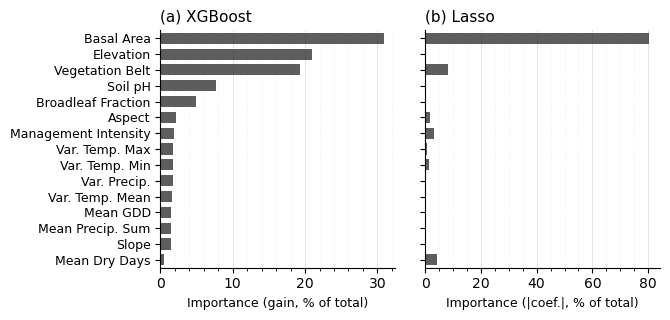

Saved: feature_importance_nfi123_broadleaf_fraction.png


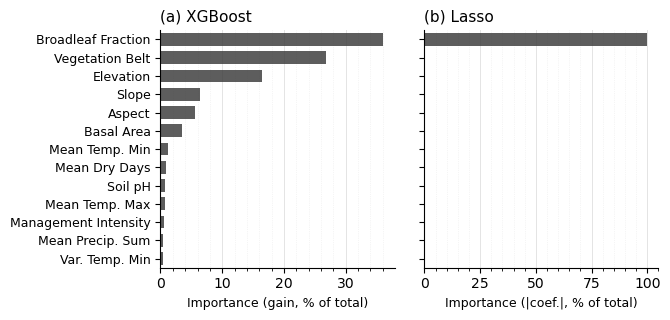

In [13]:
# --- NFI123 feature-importance figures: one figure per target (XGBoost & Lasso panels) ---

def plot_nfi123_feature_importance(nfi123_importance, n_top=15):
    targets = {
        'BASFPH_next_INVNR':    ('Next Basal Area',         'basal_area'),
        'HWSW_prop_next_INVNR': ('Next Broadleaf Fraction', 'broadleaf_fraction'),
    }
    xlabels = {'XGBoost': 'Importance (gain, % of total)', 'Lasso': 'Importance (|coef.|, % of total)'}
    panel_labels = ['(a)', '(b)']

    for target, (target_title, fstem) in targets.items():
        xgb_imp = nfi123_importance[target]['XGBoost']
        feature_order = xgb_imp[xgb_imp > 0].nlargest(n_top).index.tolist()
        readable = [feature_name_map.get(f, f) for f in feature_order]
        y_pos = np.arange(len(readable))

        fig, axes = plt.subplots(1, 2, figsize=(7, 3.5), sharey=True)
        for col, model in enumerate(['XGBoost', 'Lasso']):
            ax = axes[col]
            vals = nfi123_importance[target][model].reindex(feature_order).fillna(0).values
            ax.barh(y_pos, vals[::-1], height=0.7, color='0.25', alpha=0.85)
            if col == 0:
                ax.set_yticks(y_pos)
                ax.set_yticklabels(readable[::-1], fontsize=9)
            ax.set_ylim(-0.5, len(feature_order) - 0.5)
            ax.set_xlabel(xlabels[model], fontsize=9)
            ax.set_title(panel_labels[col] + ' ' + model, loc='left', fontsize=11)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.set_axisbelow(True)
            ax.xaxis.set_minor_locator(AutoMinorLocator())
            ax.grid(True, which='major', axis='x', linewidth=0.7, alpha=0.35)
            ax.grid(True, which='minor', axis='x', linestyle=':', linewidth=0.5, alpha=0.25)
        plt.tight_layout(pad=1.8)
        fname = f'feature_importance_nfi123_{fstem}.png'
        fig.savefig(FIG_DIR + fname, dpi=300, bbox_inches='tight')
        print('Saved:', fname)
        plt.show()

plot_nfi123_feature_importance(nfi123_importance, n_top=15)


Saved: obs_vs_pred_nfi123_nfi5_xgboost.png


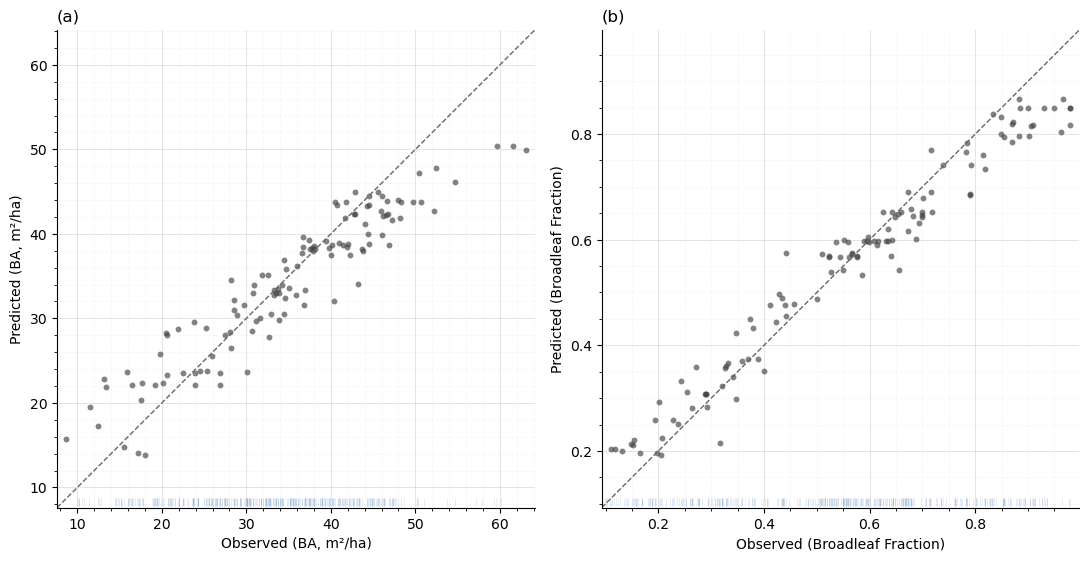

In [14]:
# --- Observed vs predicted, XGBoost only, both targets in one figure ---

def plot_obs_vs_pred_xgb(plot_data_ba, plot_data_blf, train_ba, train_blf):
    cfgs = [
        (plot_data_ba,  train_ba,  'Observed (BA, m²/ha)',          'Predicted (BA, m²/ha)',          '(a)'),
        (plot_data_blf, train_blf, 'Observed (Broadleaf Fraction)', 'Predicted (Broadleaf Fraction)', '(b)'),
    ]
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
    for ax, (pdata, train_vals, xlabel, ylabel, panel_label) in zip(axes, cfgs):
        y    = pdata['y_true']
        pred = pdata['XGBoost']
        all_v = np.concatenate([y, pred])
        lo, hi = all_v.min(), all_v.max()
        pad = 0.02 * (hi - lo); lo, hi = lo - pad, hi + pad
        ax.scatter(y, pred, s=18, alpha=0.65, color='0.25', linewidth=0)
        ax.plot([lo, hi], [lo, hi], '--', color='0.4', lw=1)
        rug_y = lo + 0.012 * (hi - lo)
        ax.plot(train_vals, np.full(len(train_vals), rug_y), '|', color='#2166ac',
                alpha=0.15, markersize=6, markeredgewidth=0.6, zorder=0)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        ax.set_aspect('equal', adjustable='box')
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
        ax.set_title(panel_label, loc='left', fontsize=12)
        ax.xaxis.set_minor_locator(AutoMinorLocator()); ax.yaxis.set_minor_locator(AutoMinorLocator())
        ax.set_axisbelow(True)
        ax.grid(True, which='major', linewidth=0.7, alpha=0.35)
        ax.grid(True, which='minor', linestyle=':', linewidth=0.5, alpha=0.25)
    plt.tight_layout(pad=1.1)
    fname = 'obs_vs_pred_nfi123_nfi5_xgboost.png'
    fig.savefig(FIG_DIR + fname, dpi=300, bbox_inches='tight')
    print('Saved:', fname)
    plt.show()

# panels list is used by the residuals cell below
panels = [
    ('BASFPH_next_INVNR',    None, 'basal_area'),
    ('HWSW_prop_next_INVNR', None, 'broadleaf_fraction'),
]

plot_obs_vs_pred_xgb(
    plot_nfi123['BASFPH_next_INVNR'],
    plot_nfi123['HWSW_prop_next_INVNR'],
    nfi123_scope['y_train']['BASFPH_next_INVNR'].values,
    nfi123_scope['y_train']['HWSW_prop_next_INVNR'].values,
)

Saved: residuals_nfi123_nfi5_basal_area_xgboost.png


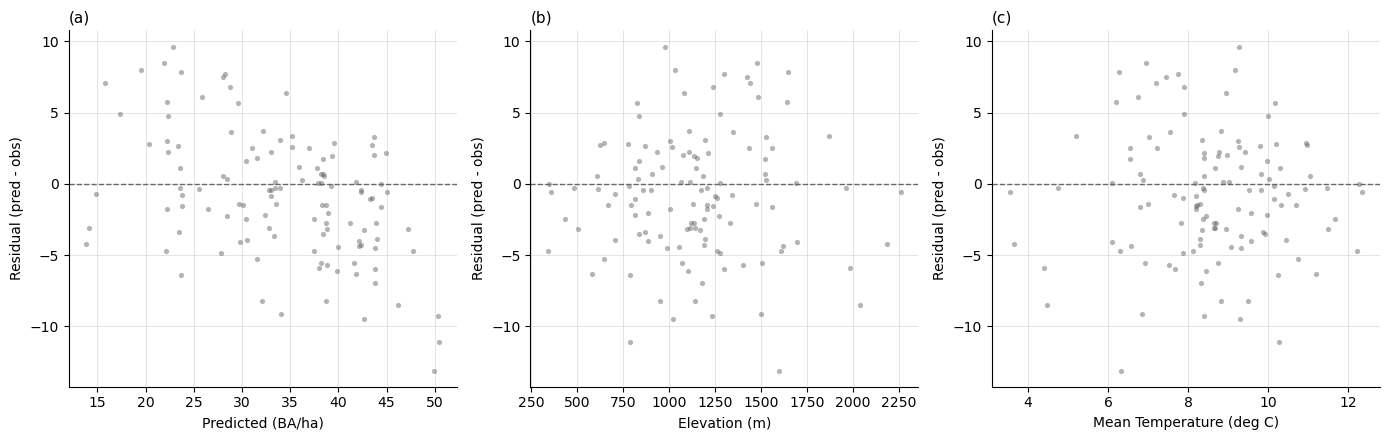

Saved: residuals_nfi123_nfi5_broadleaf_fraction_xgboost.png


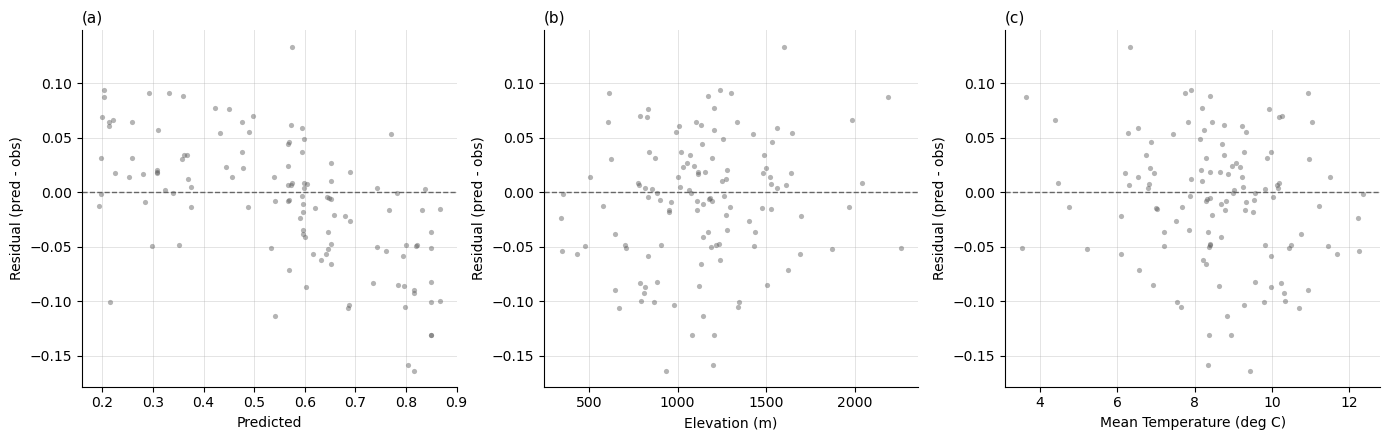

In [15]:
# --- Residual diagnostics (vs predicted / elevation / mean temp) for NFI123, XGBoost only ---

def plot_residuals(plot_data, original_df, target, fname):
    pred_xlabel = 'Predicted (BA/ha)' if target == 'BASFPH_next_INVNR' else 'Predicted'
    y_true = plot_data.get('y_true')
    if y_true is None or 'XGBoost' not in plot_data:
        return
    resid = plot_data['XGBoost'] - y_true
    pred  = plot_data['XGBoost']
    sc_kw = dict(s=14, alpha=0.45, linewidth=0, color='0.35', marker='o')
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
    axes[0].scatter(pred, resid, **sc_kw); axes[0].set_xlabel(pred_xlabel)
    axes[0].set_title('(a)', loc='left', fontsize=11)
    axes[1].scatter(original_df['Z25'].values, resid, **sc_kw); axes[1].set_xlabel('Elevation (m)')
    axes[1].set_title('(b)', loc='left', fontsize=11)
    axes[2].scatter(original_df['mean_tas_mean'].values, resid, **sc_kw)
    axes[2].set_xlabel('Mean Temperature (deg C)')
    axes[2].set_title('(c)', loc='left', fontsize=11)
    for ax in axes:
        ax.axhline(0, color='0.4', lw=1, ls='--')
        ax.set_ylabel('Residual (pred - obs)')
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        ax.set_axisbelow(True); ax.grid(True, which='major', linewidth=0.7, alpha=0.35)
    plt.tight_layout()
    fig.savefig(FIG_DIR + fname, dpi=300, bbox_inches='tight')
    print('Saved:', fname)
    plt.show()

for tag, pdata, odf in [('nfi123_nfi5', plot_nfi123, df_nfi123_test)]:
    for target, _, fstem in panels:
        plot_residuals(pdata[target], odf, target,
                       f'residuals_{tag}_{fstem}_xgboost.png')

Saved: feature_correlation_matrix.png


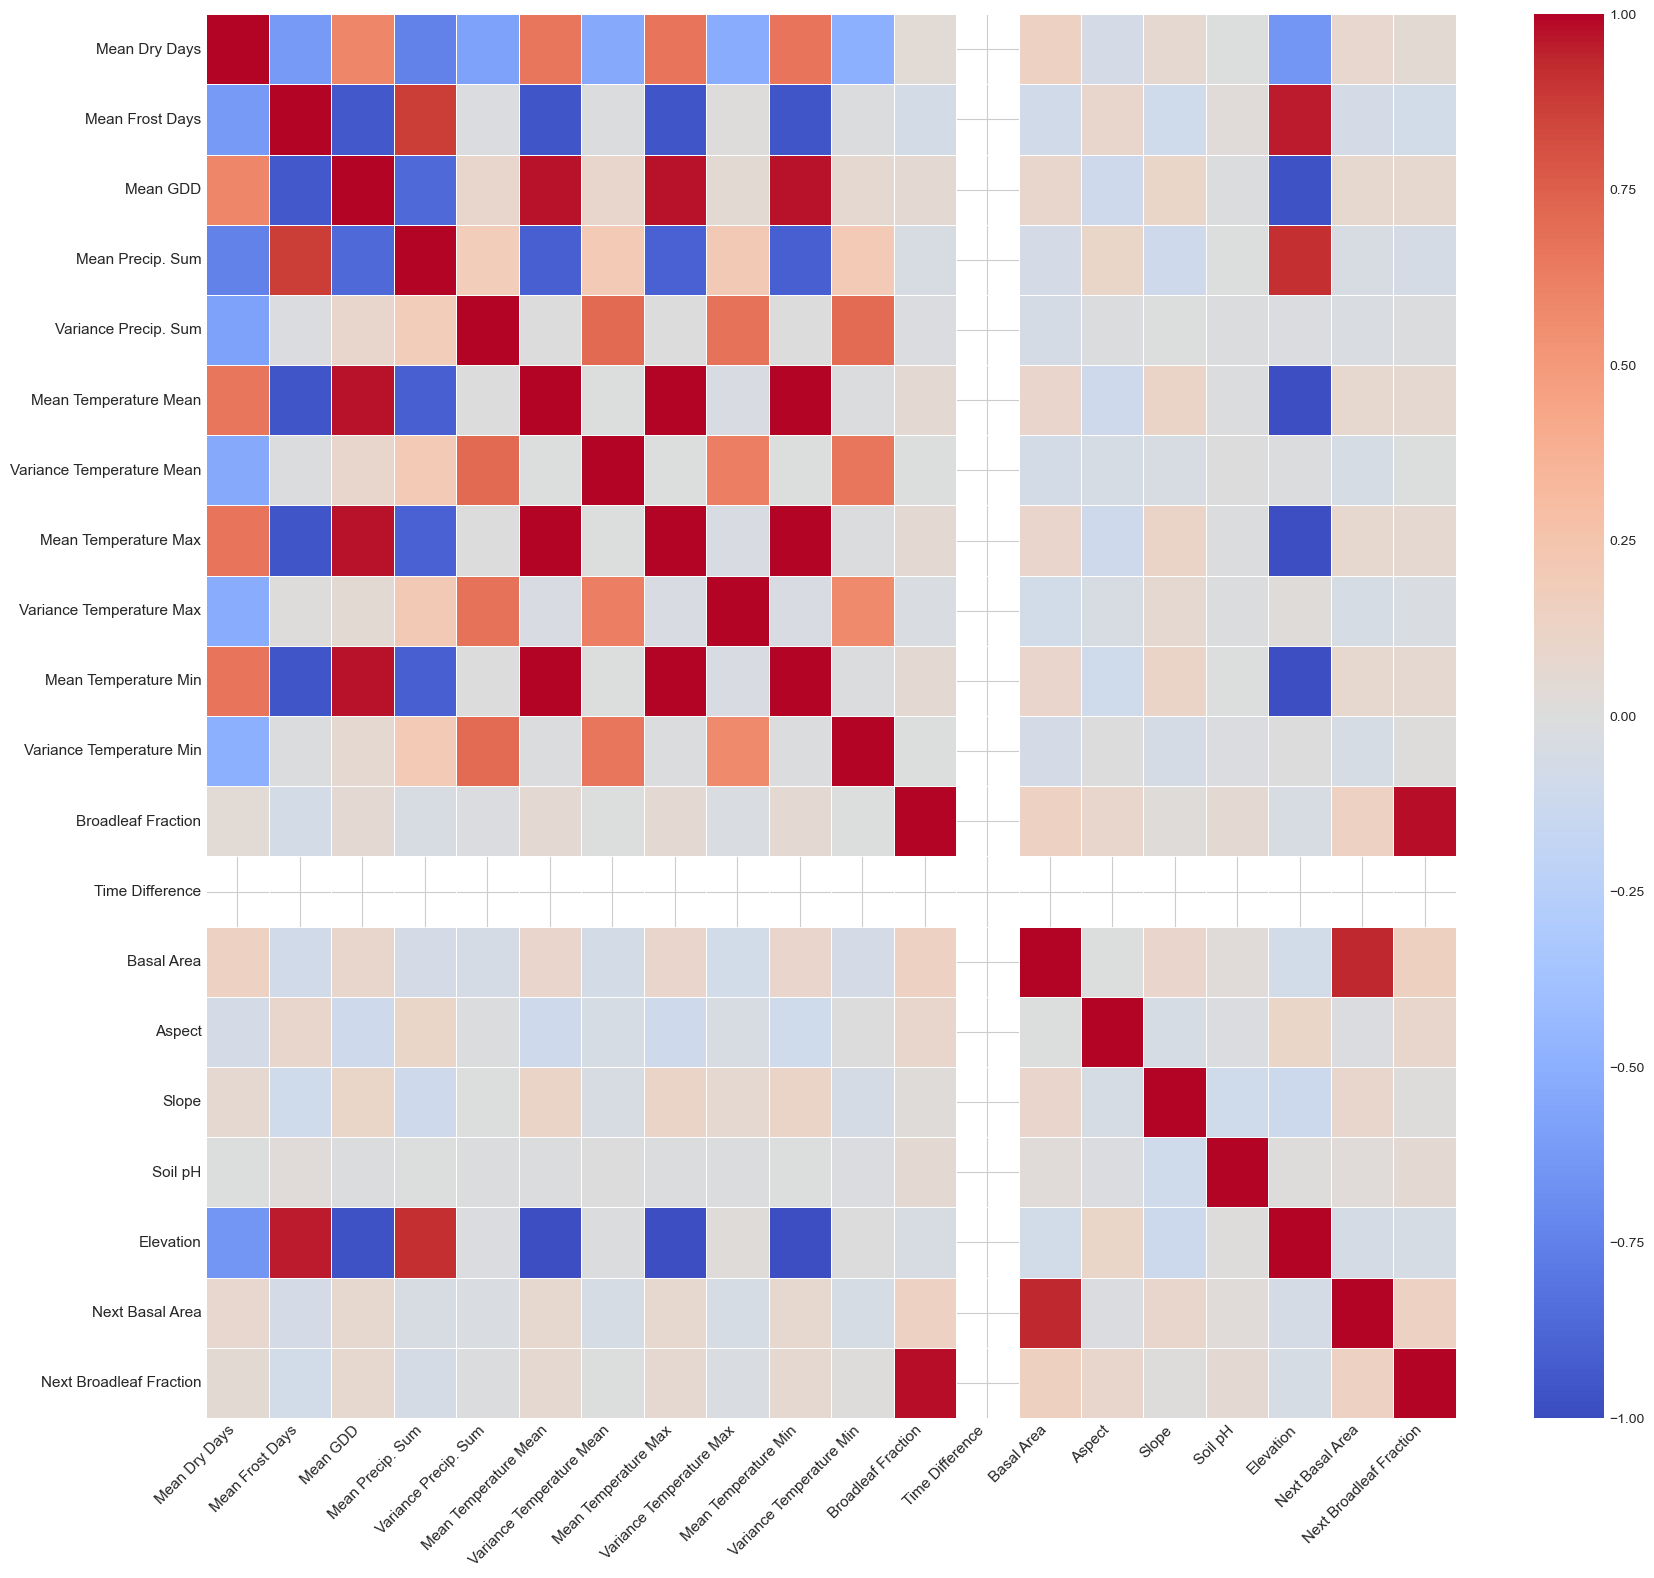

In [16]:
# --- Correlation heatmap of numerical features and targets (data-only, case-independent) ---

def create_correlation_heatmap(data, features, categorical_features):
    num_feats = [f for f in features if f not in categorical_features]
    corr = data[num_feats + TARGETS].corr()
    name_map = {
        'BASFPH': 'Basal Area', 'HWSW_prop': 'Broadleaf Fraction', 'Time_Diff_years': 'Time Difference',
        'ASPECT25': 'Aspect', 'SLOPE25': 'Slope', 'PH': 'Soil pH', 'Z25': 'Elevation',
        'mean_tasmin_mean': 'Mean Temperature Min', 'mean_tasmin_variance': 'Variance Temperature Min',
        'mean_tas_mean': 'Mean Temperature Mean', 'mean_tas_variance': 'Variance Temperature Mean',
        'mean_tasmax_mean': 'Mean Temperature Max', 'mean_tasmax_variance': 'Variance Temperature Max',
        'mean_pr_sum': 'Mean Precip. Sum', 'mean_pr_variance': 'Variance Precip. Sum',
        'mean_dry_days_count': 'Mean Dry Days', 'mean_frost_days_count': 'Mean Frost Days',
        'mean_gdd_sum': 'Mean GDD', 'BASFPH_next_INVNR': 'Next Basal Area',
        'HWSW_prop_next_INVNR': 'Next Broadleaf Fraction',
    }
    corr = corr.rename(index=lambda x: name_map.get(x, x), columns=lambda x: name_map.get(x, x))
    plt.style.use('seaborn-v0_8-whitegrid')
    plt.figure(figsize=(18, 16))
    ax = sns.heatmap(corr, annot=False, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
    plt.xticks(rotation=45, ha='right', fontsize=11); plt.yticks(fontsize=11)
    plt.tight_layout(pad=1.5)
    plt.savefig(FIG_DIR + 'feature_correlation_matrix.png', dpi=300, bbox_inches='tight')
    print('Saved: feature_correlation_matrix.png')
    plt.show()

create_correlation_heatmap(df, FEATURES, CATEGORICAL_FEATURES)